In [ ]:
from google.colab import drive
import os
from pathlib import Path

# Montar Drive para guardar el dataset
drive.mount('/content/drive')

# Ruta Drive
ruta_drive = Path('/content/drive/TU_RUTA')

Mounted at /content/drive


In [ ]:
import zipfile

# Ruta del zip
zip_path = ruta_drive/"database.sqlite.zip"

# Descomprimir el archivo
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(ruta_drive)

print("Archivo descomprimido correctamente.")
print("Contenido de la carpeta:")
for archivo in ruta_drive.iterdir():
    print(archivo.name)

Archivo descomprimido correctamente.
Contenido de la carpeta:
Dataset.gdoc
database.sqlite.zip
database.sqlite
match_features_laliga.csv


In [ ]:
import sqlite3
import pandas as pd
from pathlib import Path

# Ruta al archivo de base de datos
db_path = Path("/content/drive/MyDrive/TU_RUTA/database.sqlite")

# Conexión con SQLite
conn = sqlite3.connect(db_path)

print("Conexión realizada correctamente.")

# Consultar las tablas disponibles
query = "SELECT name FROM sqlite_master WHERE type='table';"
tablas = pd.read_sql_query(query, conn)

tablas

Conexión realizada correctamente.


,name
0,sqlite_sequence
1,Player_Attributes
2,Player
3,Match
4,League
5,Country
6,Team
7,Team_Attributes


# ANALISIS EXPLORATORIO

In [ ]:
# Vamos a comenzar con el análisis exploratorio, ya que la tabla central es MATCH de donde sacaremos el histórico de partidos

match_df = pd.read_sql_query("SELECT * FROM Match LIMIT 5;", conn)

print("Número de columnas:", len(match_df.columns))
print(match_df.columns.tolist())

# Ver el tipo de dato de cada columna
print(match_df.dtypes)

Número de columnas: 115
['id', 'country_id', 'league_id', 'season', 'stage', 'date', 'match_api_id', 'home_team_api_id', 'away_team_api_id', 'home_team_goal', 'away_team_goal', 'home_player_X1', 'home_player_X2', 'home_player_X3', 'home_player_X4', 'home_player_X5', 'home_player_X6', 'home_player_X7', 'home_player_X8', 'home_player_X9', 'home_player_X10', 'home_player_X11', 'away_player_X1', 'away_player_X2', 'away_player_X3', 'away_player_X4', 'away_player_X5', 'away_player_X6', 'away_player_X7', 'away_player_X8', 'away_player_X9', 'away_player_X10', 'away_player_X11', 'home_player_Y1', 'home_player_Y2', 'home_player_Y3', 'home_player_Y4', 'home_player_Y5', 'home_player_Y6', 'home_player_Y7', 'home_player_Y8', 'home_player_Y9', 'home_player_Y10', 'home_player_Y11', 'away_player_Y1', 'away_player_Y2', 'away_player_Y3', 'away_player_Y4', 'away_player_Y5', 'away_player_Y6', 'away_player_Y7', 'away_player_Y8', 'away_player_Y9', 'away_player_Y10', 'away_player_Y11', 'home_player_1', 'home_

In [ ]:
match_df.head()

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,...,SJA,VCH,VCD,VCA,GBH,GBD,GBA,BSH,BSD,BSA
0,1,1,1,2008/2009,1,2008-08-17 00:00:00,492473,9987,9993,1,...,4.00,1.65,3.40,4.50,1.78,3.25,4.00,1.73,3.40,4.20
1,2,1,1,2008/2009,1,2008-08-16 00:00:00,492474,10000,9994,0,...,3.80,2.00,3.25,3.25,1.85,3.25,3.75,1.91,3.25,3.60
2,3,1,1,2008/2009,1,2008-08-16 00:00:00,492475,9984,8635,0,...,2.50,2.35,3.25,2.65,2.50,3.20,2.50,2.30,3.20,2.75
3,4,1,1,2008/2009,1,2008-08-17 00:00:00,492476,9991,9998,5,...,7.50,1.45,3.75,6.50,1.50,3.75,5.50,1.44,3.75,6.50
4,5,1,1,2008/2009,1,2008-08-16 00:00:00,492477,7947,9985,1,...,1.73,4.50,3.40,1.65,4.50,3.50,1.65,4.75,3.30,1.67


La estructura de la tabla Match está clara y el siguiente paso será decidir las columnas que nos interesan para nuestr análisis. Por un lado, vemos columnas de identificación del partido, otras para ver los equipos participantes (las uniremos con la tabla Team), columnas con los goles que nos permitirán saber el resultado; las posiciones y alicneaciones de jugadores en cada partido; y columnas de cuotas de apuestas.

Como queremos predecir, es importante quedarnos con variables previas al partido, de esta taba, de momento, cogeremos datos principales.

In [ ]:
# Consultamos en la tabla League el id de la liga española para filtrar por ahí antes de crear el dataframe

league_df = pd.read_sql_query("SELECT * FROM League WHERE name LIKE '%Liga%';", conn)

print("Número de columnas:", len(league_df.columns))
print(league_df.columns.tolist())

league_df.head()

Número de columnas: 3
['id', 'country_id', 'name']


,id,country_id,name
0,7809,7809,Germany 1. Bundesliga
1,17642,17642,Portugal Liga ZON Sagres
2,21518,21518,Spain LIGA BBVA


Ya sabemos que el id de la liga española es 21518, lo cual será clave para filtrar en el dataset

In [ ]:
# Definimos las columnas base que en principio usaremos para nuestro dataset

# La etiqueta a predecir será el resultado final del partido de esta forma:
# HomeWin, Draw, AwayWin

columnas_base_match = [
    'id', 'country_id', 'league_id', 'season', 'stage', 'date',
    'match_api_id', 'home_team_api_id', 'away_team_api_id',
    'home_team_goal', 'away_team_goal',
    'B365H', 'B365D', 'B365A'
]

league_id_es = 21518

# Convertimos la lista de columnas en un string separado por comas
columnas_sql_match = ", ".join(columnas_base_match)

# Consulta SQL
query = f"SELECT {columnas_sql_match} FROM Match WHERE league_id = {league_id_es};"

# Creamos el dataset prefiltrado
match_df = pd.read_sql_query(query, conn)

# 5. Cargar el DataFrame
match_df = pd.read_sql_query(query, conn)

print("Dimensiones del DataFrame:", match_df.shape)
print(match_df.dtypes)

Dimensiones del DataFrame: (3040, 14)
id                    int64
country_id            int64
league_id             int64
season               object
stage                 int64
date                 object
match_api_id          int64
home_team_api_id      int64
away_team_api_id      int64
home_team_goal        int64
away_team_goal        int64
B365H               float64
B365D               float64
B365A               float64
dtype: object


In [ ]:
match_df.head()

,id,country_id,league_id,season,stage,date,match_api_id,home_team_api_id,away_team_api_id,home_team_goal,away_team_goal,B365H,B365D,B365A
0,21518,21518,21518,2008/2009,1,2008-08-30 00:00:00,530023,10267,8661,3,0,1.7,3.6,5.25
1,21519,21518,21518,2008/2009,1,2008-08-31 00:00:00,530084,8371,10205,1,1,2.8,3.3,2.50
2,21520,21518,21518,2008/2009,1,2008-08-31 00:00:00,530085,9783,8633,2,1,3.5,3.3,2.10
3,21521,21518,21518,2008/2009,1,2008-08-31 00:00:00,530086,8388,8634,1,0,7.0,4.0,1.50
4,21522,21518,21518,2008/2009,1,2008-08-31 00:00:00,530087,8696,8302,1,1,2.8,3.3,2.50


In [ ]:
# Valores nulos por columna
print(match_df.isnull().sum())

# Convertir la fecha a datetime
match_df["date"] = pd.to_datetime(match_df["date"])

# Comprobar tipos tras la conversión
print(match_df.dtypes)

# Ver temporadas disponibles
print(sorted(match_df["season"].unique()))

id                  0
country_id          0
league_id           0
season              0
stage               0
date                0
match_api_id        0
home_team_api_id    0
away_team_api_id    0
home_team_goal      0
away_team_goal      0
B365H               1
B365D               1
B365A               1
dtype: int64
id                           int64
country_id                   int64
league_id                    int64
season                      object
stage                        int64
date                datetime64[ns]
match_api_id                 int64
home_team_api_id             int64
away_team_api_id             int64
home_team_goal               int64
away_team_goal               int64
B365H                      float64
B365D                      float64
B365A                      float64
dtype: object
['2008/2009', '2009/2010', '2010/2011', '2011/2012', '2012/2013', '2013/2014', '2014/2015', '2015/2016']


El conjunto de datos de LaLiga española tiene 3040 partidos correspondientes a 8 temporadas desde la temporada 2008/2009 hasta la 2015/2016. Sólo existe un valor nulo en las cuotas de Bet365, lo que indica que el dataset tiene una buena calidad inicial.

In [ ]:
# Revisaremos el resto de tablas, excluyendo de momento las tablas de Player y Player_Attributes

team_df = pd.read_sql_query("SELECT * FROM Team", conn)

print("Número de columnas:", len(team_df.columns))
print(team_df.columns.tolist())

team_df.head()

Número de columnas: 5
['id', 'team_api_id', 'team_fifa_api_id', 'team_long_name', 'team_short_name']


,id,team_api_id,team_fifa_api_id,team_long_name,team_short_name
0,1,9987,673.0,KRC Genk,GEN
1,2,9993,675.0,Beerschot AC,BAC
2,3,10000,15005.0,SV Zulte-Waregem,ZUL
3,4,9994,2007.0,Sporting Lokeren,LOK
4,5,9984,1750.0,KSV Cercle Brugge,CEB


In [ ]:
team_attributes_df = pd.read_sql_query("SELECT * FROM Team_Attributes", conn)

print("Número de columnas:", len(team_attributes_df.columns))
print(team_attributes_df.columns.tolist())

team_attributes_df.head()

Número de columnas: 25
['id', 'team_fifa_api_id', 'team_api_id', 'date', 'buildUpPlaySpeed', 'buildUpPlaySpeedClass', 'buildUpPlayDribbling', 'buildUpPlayDribblingClass', 'buildUpPlayPassing', 'buildUpPlayPassingClass', 'buildUpPlayPositioningClass', 'chanceCreationPassing', 'chanceCreationPassingClass', 'chanceCreationCrossing', 'chanceCreationCrossingClass', 'chanceCreationShooting', 'chanceCreationShootingClass', 'chanceCreationPositioningClass', 'defencePressure', 'defencePressureClass', 'defenceAggression', 'defenceAggressionClass', 'defenceTeamWidth', 'defenceTeamWidthClass', 'defenceDefenderLineClass']


,id,team_fifa_api_id,team_api_id,date,buildUpPlaySpeed,buildUpPlaySpeedClass,buildUpPlayDribbling,buildUpPlayDribblingClass,buildUpPlayPassing,buildUpPlayPassingClass,...,chanceCreationShooting,chanceCreationShootingClass,chanceCreationPositioningClass,defencePressure,defencePressureClass,defenceAggression,defenceAggressionClass,defenceTeamWidth,defenceTeamWidthClass,defenceDefenderLineClass
0,1,434,9930,2010-02-22 00:00:00,60,Balanced,NaN,Little,50,Mixed,...,55,Normal,Organised,50,Medium,55,Press,45,Normal,Cover
1,2,434,9930,2014-09-19 00:00:00,52,Balanced,48.0,Normal,56,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
2,3,434,9930,2015-09-10 00:00:00,47,Balanced,41.0,Normal,54,Mixed,...,64,Normal,Organised,47,Medium,44,Press,54,Normal,Cover
3,4,77,8485,2010-02-22 00:00:00,70,Fast,NaN,Little,70,Long,...,70,Lots,Organised,60,Medium,70,Double,70,Wide,Cover
4,5,77,8485,2011-02-22 00:00:00,47,Balanced,NaN,Little,52,Mixed,...,52,Normal,Organised,47,Medium,47,Press,52,Normal,Cover


In [ ]:
country_df = pd.read_sql_query("SELECT * FROM Country", conn)

print("Número de columnas:", len(country_df.columns))
print(country_df.columns.tolist())

country_df.head()

Número de columnas: 2
['id', 'name']


,id,name
0,1,Belgium
1,1729,England
2,4769,France
3,7809,Germany
4,10257,Italy


Tras observar el resto de tablas de nuestra base de datos, excluyendo inicialmente el análisis de los jugadores y sus atributos, enriqueceremos nuestro dataset de Match con el nombre de los equipos locales y visitantes.

Por otro lado, vamos a usar la tabla de los atributos de cada equipo, ya que es bastante interesante, pero será una tabla que, vemos que cambia con el tiempo, por lo que probablemente la utilziaremos para sacar un histórico.

In [ ]:
# No nos traemos las columnas country_id ni league_id a nuestro dataset, ya que está prefiltrado por LaLiga española y no aporta nada relevante

query = """
SELECT
    m.id,
    m.season,
    m.stage,
    m.date,
    m.match_api_id,
    m.home_team_api_id,
    ht.team_long_name AS home_team_name,
    ht.team_short_name AS home_team_name_short,
    m.away_team_api_id,
    at.team_long_name AS away_team_name,
    at.team_short_name AS away_team_name_short,
    m.home_team_goal,
    m.away_team_goal,
    m.B365H,
    m.B365D,
    m.B365A
FROM Match m
LEFT JOIN Team ht
    ON m.home_team_api_id = ht.team_api_id
LEFT JOIN Team at
    ON m.away_team_api_id = at.team_api_id
WHERE m.league_id = 21518
"""

match_df = pd.read_sql_query(query, conn)
match_df.head()

,id,season,stage,date,match_api_id,home_team_api_id,home_team_name,home_team_name_short,away_team_api_id,away_team_name,away_team_name_short,home_team_goal,away_team_goal,B365H,B365D,B365A
0,21518,2008/2009,1,2008-08-30 00:00:00,530023,10267,Valencia CF,VAL,8661,RCD Mallorca,MAL,3,0,1.7,3.6,5.25
1,21519,2008/2009,1,2008-08-31 00:00:00,530084,8371,CA Osasuna,OSA,10205,Villarreal CF,VIL,1,1,2.8,3.3,2.50
2,21520,2008/2009,1,2008-08-31 00:00:00,530085,9783,RC Deportivo de La Coruña,COR,8633,Real Madrid CF,REA,2,1,3.5,3.3,2.10
3,21521,2008/2009,1,2008-08-31 00:00:00,530086,8388,CD Numancia,NUM,8634,FC Barcelona,BAR,1,0,7.0,4.0,1.50
4,21522,2008/2009,1,2008-08-31 00:00:00,530087,8696,Racing Santander,SAN,8302,Sevilla FC,SEV,1,1,2.8,3.3,2.50


In [ ]:
# Crear variable objetivo multiclase
def crear_resultado(row):
    if row["home_team_goal"] > row["away_team_goal"]:
        return "HomeWin"
    elif row["home_team_goal"] == row["away_team_goal"]:
        return "Draw"
    else:
        return "AwayWin"

match_df["result"] = match_df.apply(crear_resultado, axis=1)

# Revisar distribución
print(match_df["result"].value_counts())
print(match_df["result"].value_counts(normalize=True))

result
HomeWin    1485
AwayWin     851
Draw        704
Name: count, dtype: int64
result
HomeWin    0.488487
AwayWin    0.279934
Draw       0.231579
Name: proportion, dtype: float64


In [ ]:
match_df = match_df.sort_values(["season", "date", "match_api_id"]).reset_index(drop=True)

In [ ]:
# Comprobar resultado
print(match_df[["date", "home_team_goal", "away_team_goal", "result"]].head())

# Distribución de clases
print("\nDistribución absoluta:")
print(match_df["result"].value_counts())

print("\nDistribución relativa:")
print(match_df["result"].value_counts(normalize=True))

                  date  home_team_goal  away_team_goal   result
0  2008-08-30 00:00:00               3               0  HomeWin
1  2008-08-30 00:00:00               1               0  HomeWin
2  2008-08-31 00:00:00               1               1     Draw
3  2008-08-31 00:00:00               2               1  HomeWin
4  2008-08-31 00:00:00               1               0  HomeWin

Distribución absoluta:
result
HomeWin    1485
AwayWin     851
Draw        704
Name: count, dtype: int64

Distribución relativa:
result
HomeWin    0.488487
AwayWin    0.279934
Draw       0.231579
Name: proportion, dtype: float64


La variable objetivo se definió como una clasificación multiclase con tres posibles resultados del partido: victoria local, empate y victoria visitante.

Tras ver las distribuciones de resultados, vemos que la victoria local se da en el 48,84% de los partidos, lo cual es bastante coherente con el hecho de que jugar en casa en el fútbol supone una ventaja.

Hay cierto desbalance en nuestra variable objetivo, ya que hay más datos de victorias locales que de empates y victorias visitantes, lo cual será un factor a tener en cuenta en el futuro

In [ ]:
# Analizaremos la tabla Team_Attributes, ya que puede ser una tabla interesante para construir un histórico a raiz de ella

print(team_attributes_df.dtypes)
print(team_attributes_df.isnull().sum())
print(team_attributes_df.shape)

id                                  int64
team_fifa_api_id                    int64
team_api_id                         int64
date                               object
buildUpPlaySpeed                    int64
buildUpPlaySpeedClass              object
buildUpPlayDribbling              float64
buildUpPlayDribblingClass          object
buildUpPlayPassing                  int64
buildUpPlayPassingClass            object
buildUpPlayPositioningClass        object
chanceCreationPassing               int64
chanceCreationPassingClass         object
chanceCreationCrossing              int64
chanceCreationCrossingClass        object
chanceCreationShooting              int64
chanceCreationShootingClass        object
chanceCreationPositioningClass     object
defencePressure                     int64
defencePressureClass               object
defenceAggression                   int64
defenceAggressionClass             object
defenceTeamWidth                    int64
defenceTeamWidthClass             

In [ ]:
# Ver cuántos registros hay por equipo

registros_por_equipo = pd.read_sql_query("""
SELECT
    team_api_id,
    COUNT(*) AS num_registros
FROM Team_Attributes
GROUP BY team_api_id
ORDER BY num_registros DESC;
""", conn)

registros_por_equipo.head(10)

,team_api_id,num_registros
0,108893,6
1,10281,6
2,10269,6
3,10268,6
4,10267,6
5,10265,6
6,10264,6
7,10261,6
8,10260,6
9,10252,6


In [ ]:
fechas_team_attr = pd.read_sql_query("""
SELECT
    MIN(date) AS fecha_min,
    MAX(date) AS fecha_max
FROM Team_Attributes;
""", conn)

fechas_team_attr

,fecha_min,fecha_max
0,2010-02-22 00:00:00,2015-09-10 00:00:00


In [ ]:
# Vemos si los equipos de LaLiga están representados

equipos_match = set(match_df["home_team_api_id"]).union(set(match_df["away_team_api_id"]))
equipos_attr = set(team_attributes_df["team_api_id"].unique())

equipos_sin_attr = equipos_match - equipos_attr

print("Número de equipos en match_df:", len(equipos_match))
print("Número de equipos con atributos:", len(equipos_match.intersection(equipos_attr)))
print("Número de equipos sin atributos:", len(equipos_sin_attr))
print("Equipos sin atributos:", equipos_sin_attr)

Número de equipos en match_df: 33
Número de equipos con atributos: 33
Número de equipos sin atributos: 0
Equipos sin atributos: set()


Podemos ver que en esta tabla tenemos a los equipos de LaLiga representados, que sólo la columna buildUpPlayDribbling tiene nulos (la exlcuiremos) y que dos tenemos una limitación temporal importante. La primera es que, al tener 6 registros por equipo, tenemos una fotografía periódica del estilo de juego por temporada. La segunda es que la tabla comienza en 2010, mientras que lo partidos de las dos temporadas previas no tienen atributos.

Esta tabla podrá ser interesante para incorporarla a posteriori, pero el núcleo de nuestro análisis se centrará en otras variables de entrada.

# PREPARACION DE DATOS

Para construir el histórico con el que sacar datos para entrenar al modelo, crearemos una tabla intermedia donde habrá dos filas por partido representando cada una de las filas a cada equipo

In [ ]:
# CONSTRUCCION DE LA TABLA CON 1 FILA POR EQUIPO Y PARTIDO

# Para el equipo local
home_view = match_df[
    [
        "match_api_id", "season", "stage", "date",
        "home_team_api_id", "home_team_name",
        "away_team_api_id", "away_team_name",
        "home_team_goal", "away_team_goal"
    ]
].copy()

home_view.columns = [
    "match_api_id", "season", "stage", "date",
    "team_api_id", "team_name",
    "opponent_api_id", "opponent_name",
    "goals_for", "goals_against"
]

home_view["is_home"] = 1

# Para equipo visitante
away_view = match_df[
    [
        "match_api_id", "season", "stage", "date",
        "away_team_api_id", "away_team_name",
        "home_team_api_id", "home_team_name",
        "away_team_goal", "home_team_goal"
    ]
].copy()

away_view.columns = [
    "match_api_id", "season", "stage", "date",
    "team_api_id", "team_name",
    "opponent_api_id", "opponent_name",
    "goals_for", "goals_against"
]

away_view["is_home"] = 0

# UNION AMBAS VISTAS
team_match_df = pd.concat([home_view, away_view], ignore_index=True)

# Orden cronológico por equipo
team_match_df = team_match_df.sort_values(
    ["team_api_id", "date", "match_api_id"]
).reset_index(drop=True)

print(team_match_df.shape)
team_match_df.head()

(6080, 11)


,match_api_id,season,stage,date,team_api_id,team_name,opponent_api_id,opponent_name,goals_for,goals_against,is_home
0,1778042,2014/2015,1,2014-08-25 00:00:00,7869,Córdoba CF,8633,Real Madrid CF,0,2,0
1,1778047,2014/2015,2,2014-08-30 00:00:00,7869,Córdoba CF,9910,RC Celta de Vigo,1,1,1
2,1778056,2014/2015,3,2014-09-12 00:00:00,7869,Córdoba CF,9865,UD Almería,1,1,0
3,1778066,2014/2015,4,2014-09-21 00:00:00,7869,Córdoba CF,8302,Sevilla FC,1,3,1
4,1778075,2014/2015,5,2014-09-25 00:00:00,7869,Córdoba CF,10267,Valencia CF,0,3,0


In [ ]:
# CREACION DE VARIABLES BÁSICAS PRE-PARTIDO

import numpy as np

# Puntos del partido
team_match_df["points"] = np.select(
    [
        team_match_df["goals_for"] > team_match_df["goals_against"],
        team_match_df["goals_for"] == team_match_df["goals_against"]
    ],
    [3, 1],
    default=0
)

# Indicadores binarios de resultado
team_match_df["win"] = (team_match_df["goals_for"] > team_match_df["goals_against"]).astype(int)
team_match_df["draw"] = (team_match_df["goals_for"] == team_match_df["goals_against"]).astype(int)
team_match_df["loss"] = (team_match_df["goals_for"] < team_match_df["goals_against"]).astype(int)

# Diferencia de goles del partido
team_match_df["goal_diff"] = team_match_df["goals_for"] - team_match_df["goals_against"]

team_match_df.head()

,match_api_id,season,stage,date,team_api_id,team_name,opponent_api_id,opponent_name,goals_for,goals_against,is_home,points,win,draw,loss,goal_diff
0,1778042,2014/2015,1,2014-08-25 00:00:00,7869,Córdoba CF,8633,Real Madrid CF,0,2,0,0,0,0,1,-2
1,1778047,2014/2015,2,2014-08-30 00:00:00,7869,Córdoba CF,9910,RC Celta de Vigo,1,1,1,1,0,1,0,0
2,1778056,2014/2015,3,2014-09-12 00:00:00,7869,Córdoba CF,9865,UD Almería,1,1,0,1,0,1,0,0
3,1778066,2014/2015,4,2014-09-21 00:00:00,7869,Córdoba CF,8302,Sevilla FC,1,3,1,0,0,0,1,-2
4,1778075,2014/2015,5,2014-09-25 00:00:00,7869,Córdoba CF,10267,Valencia CF,0,3,0,0,0,0,1,-3


In [ ]:
# VARIABLES ROLLING DE ULTIMOS 5 PARTIDOS

# Funciones auxiliares
def rolling_sum_prev(series, window=5):
    return series.shift(1).rolling(window=window, min_periods=1).sum()

def rolling_mean_prev(series, window=5):
    return series.shift(1).rolling(window=window, min_periods=1).mean()

# Puntos y resultados últimos 5 partidos
team_match_df["points_last5"] = (
    team_match_df.groupby(["team_api_id", "season"])["points"]
    .transform(lambda s: rolling_sum_prev(s, 5))
)

team_match_df["wins_last5"] = (
    team_match_df.groupby(["team_api_id", "season"])["win"]
    .transform(lambda s: rolling_sum_prev(s, 5))
)

team_match_df["draws_last5"] = (
    team_match_df.groupby(["team_api_id", "season"])["draw"]
    .transform(lambda s: rolling_sum_prev(s, 5))
)

team_match_df["losses_last5"] = (
    team_match_df.groupby(["team_api_id", "season"])["loss"]
    .transform(lambda s: rolling_sum_prev(s, 5))
)

# Medias de goles a favor y en contra en los últimos 5
team_match_df["avg_goals_for_last5"] = (
    team_match_df.groupby(["team_api_id", "season"])["goals_for"]
    .transform(lambda s: rolling_mean_prev(s, 5))
)

team_match_df["avg_goals_against_last5"] = (
    team_match_df.groupby(["team_api_id", "season"])["goals_against"]
    .transform(lambda s: rolling_mean_prev(s, 5))
)

team_match_df.head()

,match_api_id,season,stage,date,team_api_id,team_name,opponent_api_id,opponent_name,goals_for,goals_against,...,win,draw,loss,goal_diff,points_last5,wins_last5,draws_last5,losses_last5,avg_goals_for_last5,avg_goals_against_last5
0,1778042,2014/2015,1,2014-08-25 00:00:00,7869,Córdoba CF,8633,Real Madrid CF,0,2,...,0,0,1,-2,NaN,NaN,NaN,NaN,NaN,NaN
1,1778047,2014/2015,2,2014-08-30 00:00:00,7869,Córdoba CF,9910,RC Celta de Vigo,1,1,...,0,1,0,0,0.0,0.0,0.0,1.0,0.000000,2.000000
2,1778056,2014/2015,3,2014-09-12 00:00:00,7869,Córdoba CF,9865,UD Almería,1,1,...,0,1,0,0,1.0,0.0,1.0,1.0,0.500000,1.500000
3,1778066,2014/2015,4,2014-09-21 00:00:00,7869,Córdoba CF,8302,Sevilla FC,1,3,...,0,0,1,-2,2.0,0.0,2.0,1.0,0.666667,1.333333
4,1778075,2014/2015,5,2014-09-25 00:00:00,7869,Córdoba CF,10267,Valencia CF,0,3,...,0,0,1,-3,2.0,0.0,2.0,2.0,0.750000,1.750000


Creación de variables rolling de los últimos 5 partidos por equipo:
- Puntos
- Victorias
- Empates
- Derrotas
- Medias de goles a favor y en contra

Este rolling se reiniciará cada temporada, ya que queremos saber el estado de forma del equipo en cada temporada, puesto que de una temporada a otra pueden cambiar plantillas, entrenadores...

In [ ]:
# HISTÓRICO ACUMULADO GLOBAL PREVIO

# Número de partidos previos jugados
team_match_df["matches_played_prev"] = team_match_df.groupby("team_api_id").cumcount()

# Medias acumuladas previas
team_match_df["avg_goals_for_prev"] = (
    team_match_df.groupby("team_api_id")["goals_for"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

team_match_df["avg_goals_against_prev"] = (
    team_match_df.groupby("team_api_id")["goals_against"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

team_match_df["points_per_game_prev"] = (
    team_match_df.groupby("team_api_id")["points"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

team_match_df.head()

,match_api_id,season,stage,date,team_api_id,team_name,opponent_api_id,opponent_name,goals_for,goals_against,...,points_last5,wins_last5,draws_last5,losses_last5,avg_goals_for_last5,avg_goals_against_last5,matches_played_prev,avg_goals_for_prev,avg_goals_against_prev,points_per_game_prev
0,1778042,2014/2015,1,2014-08-25 00:00:00,7869,Córdoba CF,8633,Real Madrid CF,0,2,...,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN
1,1778047,2014/2015,2,2014-08-30 00:00:00,7869,Córdoba CF,9910,RC Celta de Vigo,1,1,...,0.0,0.0,0.0,1.0,0.000000,2.000000,1,0.000000,2.000000,0.000000
2,1778056,2014/2015,3,2014-09-12 00:00:00,7869,Córdoba CF,9865,UD Almería,1,1,...,1.0,0.0,1.0,1.0,0.500000,1.500000,2,0.500000,1.500000,0.500000
3,1778066,2014/2015,4,2014-09-21 00:00:00,7869,Córdoba CF,8302,Sevilla FC,1,3,...,2.0,0.0,2.0,1.0,0.666667,1.333333,3,0.666667,1.333333,0.666667
4,1778075,2014/2015,5,2014-09-25 00:00:00,7869,Córdoba CF,10267,Valencia CF,0,3,...,2.0,0.0,2.0,2.0,0.750000,1.750000,4,0.750000,1.750000,0.500000


Creación de variables acumuladas históricamente del número de partidos jugados y las medias de goles y puntos acumulados previas

In [ ]:
# RENDIMIENTO HISTÓRICO DEL LOCAL EN CASA Y DEL VISITANTE FUERA DE CASA

# Inicializar columnas
team_match_df["home_points_per_game_prev"] = np.nan
team_match_df["home_avg_goals_for_prev"] = np.nan
team_match_df["home_avg_goals_against_prev"] = np.nan

team_match_df["away_points_per_game_prev"] = np.nan
team_match_df["away_avg_goals_for_prev"] = np.nan
team_match_df["away_avg_goals_against_prev"] = np.nan

# Máscaras
mask_home = team_match_df["is_home"] == 1
mask_away = team_match_df["is_home"] == 0

# Histórico solo en partidos jugados como local
team_match_df.loc[mask_home, "home_points_per_game_prev"] = (
    team_match_df.loc[mask_home]
    .groupby("team_api_id")["points"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

team_match_df.loc[mask_home, "home_avg_goals_for_prev"] = (
    team_match_df.loc[mask_home]
    .groupby("team_api_id")["goals_for"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

team_match_df.loc[mask_home, "home_avg_goals_against_prev"] = (
    team_match_df.loc[mask_home]
    .groupby("team_api_id")["goals_against"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

# Histórico solo en partidos jugados como visitante
team_match_df.loc[mask_away, "away_points_per_game_prev"] = (
    team_match_df.loc[mask_away]
    .groupby("team_api_id")["points"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

team_match_df.loc[mask_away, "away_avg_goals_for_prev"] = (
    team_match_df.loc[mask_away]
    .groupby("team_api_id")["goals_for"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

team_match_df.loc[mask_away, "away_avg_goals_against_prev"] = (
    team_match_df.loc[mask_away]
    .groupby("team_api_id")["goals_against"]
    .transform(lambda s: s.shift(1).expanding().mean())
)

team_match_df.head()

,match_api_id,season,stage,date,team_api_id,team_name,opponent_api_id,opponent_name,goals_for,goals_against,...,matches_played_prev,avg_goals_for_prev,avg_goals_against_prev,points_per_game_prev,home_points_per_game_prev,home_avg_goals_for_prev,home_avg_goals_against_prev,away_points_per_game_prev,away_avg_goals_for_prev,away_avg_goals_against_prev
0,1778042,2014/2015,1,2014-08-25 00:00:00,7869,Córdoba CF,8633,Real Madrid CF,0,2,...,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1778047,2014/2015,2,2014-08-30 00:00:00,7869,Córdoba CF,9910,RC Celta de Vigo,1,1,...,1,0.000000,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN
2,1778056,2014/2015,3,2014-09-12 00:00:00,7869,Córdoba CF,9865,UD Almería,1,1,...,2,0.500000,1.500000,0.500000,NaN,NaN,NaN,0.0,0.0,2.0
3,1778066,2014/2015,4,2014-09-21 00:00:00,7869,Córdoba CF,8302,Sevilla FC,1,3,...,3,0.666667,1.333333,0.666667,1.0,1.0,1.0,NaN,NaN,NaN
4,1778075,2014/2015,5,2014-09-25 00:00:00,7869,Córdoba CF,10267,Valencia CF,0,3,...,4,0.750000,1.750000,0.500000,NaN,NaN,NaN,0.5,0.5,1.5


Creamos variables para tener el rendimiento histórico del local y del visitante fuera. Estas variables no se reinician por temporada, ya que es interesante tener en cuenta el contexto global histórico de los equipos

In [ ]:
# VARIABLES DE CONTEXTO POR TEMPORADA

# Puntos acumulados previos en la temporada
team_match_df["points_season_so_far"] = (
    team_match_df.groupby(["team_api_id", "season"])["points"]
    .transform(lambda s: s.shift(1).cumsum())
)

# Diferencia de goles acumulada previa en la temporada
team_match_df["goal_diff_season_so_far"] = (
    team_match_df.groupby(["team_api_id", "season"])["goal_diff"]
    .transform(lambda s: s.shift(1).cumsum())
)

# Rellenar primeros partidos de temporada con 0
team_match_df["points_season_so_far"] = team_match_df["points_season_so_far"].fillna(0)
team_match_df["goal_diff_season_so_far"] = team_match_df["goal_diff_season_so_far"].fillna(0)

team_match_df.head()

,match_api_id,season,stage,date,team_api_id,team_name,opponent_api_id,opponent_name,goals_for,goals_against,...,avg_goals_against_prev,points_per_game_prev,home_points_per_game_prev,home_avg_goals_for_prev,home_avg_goals_against_prev,away_points_per_game_prev,away_avg_goals_for_prev,away_avg_goals_against_prev,points_season_so_far,goal_diff_season_so_far
0,1778042,2014/2015,1,2014-08-25 00:00:00,7869,Córdoba CF,8633,Real Madrid CF,0,2,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0
1,1778047,2014/2015,2,2014-08-30 00:00:00,7869,Córdoba CF,9910,RC Celta de Vigo,1,1,...,2.000000,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,0.0,-2.0
2,1778056,2014/2015,3,2014-09-12 00:00:00,7869,Córdoba CF,9865,UD Almería,1,1,...,1.500000,0.500000,NaN,NaN,NaN,0.0,0.0,2.0,1.0,-2.0
3,1778066,2014/2015,4,2014-09-21 00:00:00,7869,Córdoba CF,8302,Sevilla FC,1,3,...,1.333333,0.666667,1.0,1.0,1.0,NaN,NaN,NaN,2.0,-2.0
4,1778075,2014/2015,5,2014-09-25 00:00:00,7869,Córdoba CF,10267,Valencia CF,0,3,...,1.750000,0.500000,NaN,NaN,NaN,0.5,0.5,1.5,2.0,-4.0


In [ ]:
# POSICION EN LA CLASIFICACION ANTES DEL PARTIDO

# Orden correcto dentro de cada temporada
team_match_df = team_match_df.sort_values(
    ["season", "date", "match_api_id", "team_api_id"]
).reset_index(drop=True)

# Inicializar columna
team_match_df["table_position"] = np.nan

# Calcular clasificación previa por temporada y por partido
for season in team_match_df["season"].unique():
    season_mask = team_match_df["season"] == season
    season_df = team_match_df.loc[season_mask].copy()

    # Partidos de esa temporada en orden cronológico
    match_ids = season_df["match_api_id"].drop_duplicates().tolist()

    # Estado acumulado de la clasificación
    tabla = {}

    posiciones = []

    for match_id in match_ids:
        match_rows = season_df[season_df["match_api_id"] == match_id].copy()

        # Antes de jugar el partido: calcular la clasificación actual
        tabla_df = pd.DataFrame.from_dict(tabla, orient="index")
        if not tabla_df.empty:
            tabla_df = tabla_df.reset_index().rename(columns={"index": "team_api_id"})
            tabla_df = tabla_df.sort_values(
                by=["points", "goal_diff", "goals_for"],
                ascending=[False, False, False]
            ).reset_index(drop=True)
            tabla_df["table_position"] = np.arange(1, len(tabla_df) + 1)

            pos_dict = dict(zip(tabla_df["team_api_id"], tabla_df["table_position"]))
        else:
            pos_dict = {}

        # Asignar posición previa a los dos equipos del partido
        for idx, row in match_rows.iterrows():
            posiciones.append(
                (idx, pos_dict.get(row["team_api_id"], np.nan))
            )

        # Actualizar la tabla tras el partido
        for _, row in match_rows.iterrows():
            team_id = row["team_api_id"]
            if team_id not in tabla:
                tabla[team_id] = {"points": 0, "goal_diff": 0, "goals_for": 0}

            tabla[team_id]["points"] += row["points"]
            tabla[team_id]["goal_diff"] += row["goal_diff"]
            tabla[team_id]["goals_for"] += row["goals_for"]

    # Volcar posiciones al dataframe original
    for idx, pos in posiciones:
        team_match_df.at[idx, "table_position"] = pos

team_match_df.head()

,match_api_id,season,stage,date,team_api_id,team_name,opponent_api_id,opponent_name,goals_for,goals_against,...,points_per_game_prev,home_points_per_game_prev,home_avg_goals_for_prev,home_avg_goals_against_prev,away_points_per_game_prev,away_avg_goals_for_prev,away_avg_goals_against_prev,points_season_so_far,goal_diff_season_so_far,table_position
0,530023,2008/2009,1,2008-08-30 00:00:00,8661,RCD Mallorca,10267,Valencia CF,0,3,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
1,530023,2008/2009,1,2008-08-30 00:00:00,10267,Valencia CF,8661,RCD Mallorca,3,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
2,530090,2008/2009,1,2008-08-30 00:00:00,8558,RCD Espanyol,10281,Real Valladolid,1,0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
3,530090,2008/2009,1,2008-08-30 00:00:00,10281,Real Valladolid,8558,RCD Espanyol,0,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
4,530084,2008/2009,1,2008-08-31 00:00:00,8371,CA Osasuna,10205,Villarreal CF,1,1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN


In [ ]:
# Separamos las features de local y visitante para volver a una fila por partido

home_features = team_match_df[team_match_df["is_home"] == 1][[
    "match_api_id",
    "matches_played_prev",
    "points_last5",
    "wins_last5",
    "draws_last5",
    "losses_last5",
    "avg_goals_for_last5",
    "avg_goals_against_last5",
    "avg_goals_for_prev",
    "avg_goals_against_prev",
    "points_per_game_prev",
    "home_points_per_game_prev",
    "home_avg_goals_for_prev",
    "home_avg_goals_against_prev",
    "points_season_so_far",
    "goal_diff_season_so_far",
    "table_position"
]].copy()

home_features = home_features.rename(columns={
    "matches_played_prev": "home_matches_played_prev",
    "points_last5": "home_points_last5",
    "wins_last5": "home_wins_last5",
    "draws_last5": "home_draws_last5",
    "losses_last5": "home_losses_last5",
    "avg_goals_for_last5": "home_avg_goals_for_last5",
    "avg_goals_against_last5": "home_avg_goals_against_last5",
    "avg_goals_for_prev": "home_avg_goals_for_prev",
    "avg_goals_against_prev": "home_avg_goals_against_prev",
    "points_per_game_prev": "home_points_per_game_prev",
    "home_points_per_game_prev": "home_home_points_per_game_prev",
    "home_avg_goals_for_prev": "home_home_avg_goals_for_prev",
    "home_avg_goals_against_prev": "home_home_avg_goals_against_prev",
    "points_season_so_far": "home_points_season_so_far",
    "goal_diff_season_so_far": "home_goal_diff_season_so_far",
    "table_position": "home_table_position"
})

In [ ]:
away_features = team_match_df[team_match_df["is_home"] == 0][[
    "match_api_id",
    "matches_played_prev",
    "points_last5",
    "wins_last5",
    "draws_last5",
    "losses_last5",
    "avg_goals_for_last5",
    "avg_goals_against_last5",
    "avg_goals_for_prev",
    "avg_goals_against_prev",
    "points_per_game_prev",
    "away_points_per_game_prev",
    "away_avg_goals_for_prev",
    "away_avg_goals_against_prev",
    "points_season_so_far",
    "goal_diff_season_so_far",
    "table_position"
]].copy()

away_features = away_features.rename(columns={
    "matches_played_prev": "away_matches_played_prev",
    "points_last5": "away_points_last5",
    "wins_last5": "away_wins_last5",
    "draws_last5": "away_draws_last5",
    "losses_last5": "away_losses_last5",
    "avg_goals_for_last5": "away_avg_goals_for_last5",
    "avg_goals_against_last5": "away_avg_goals_against_last5",
    "avg_goals_for_prev": "away_avg_goals_for_prev",
    "avg_goals_against_prev": "away_avg_goals_against_prev",
    "points_per_game_prev": "away_points_per_game_prev",
    "away_points_per_game_prev": "away_away_points_per_game_prev",
    "away_avg_goals_for_prev": "away_away_avg_goals_for_prev",
    "away_avg_goals_against_prev": "away_away_avg_goals_against_prev",
    "points_season_so_far": "away_points_season_so_far",
    "goal_diff_season_so_far": "away_goal_diff_season_so_far",
    "table_position": "away_table_position"
})

In [ ]:
match_features_df = match_df.merge(home_features, on="match_api_id", how="left")
match_features_df = match_features_df.merge(away_features, on="match_api_id", how="left")

print(match_features_df.shape)
match_features_df.head()

(3040, 49)


,id,season,stage,date,match_api_id,home_team_api_id,home_team_name,home_team_name_short,away_team_api_id,away_team_name,...,away_avg_goals_against_last5,away_avg_goals_for_prev,away_avg_goals_against_prev,away_points_per_game_prev,away_away_points_per_game_prev,away_away_avg_goals_for_prev,away_away_avg_goals_against_prev,away_points_season_so_far,away_goal_diff_season_so_far,away_table_position
0,21518,2008/2009,1,2008-08-30 00:00:00,530023,10267,Valencia CF,VAL,8661,RCD Mallorca,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
1,21525,2008/2009,1,2008-08-30 00:00:00,530090,8558,RCD Espanyol,ESP,10281,Real Valladolid,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
2,21519,2008/2009,1,2008-08-31 00:00:00,530084,8371,CA Osasuna,OSA,10205,Villarreal CF,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
3,21520,2008/2009,1,2008-08-31 00:00:00,530085,9783,RC Deportivo de La Coruña,COR,8633,Real Madrid CF,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
4,21521,2008/2009,1,2008-08-31 00:00:00,530086,8388,CD Numancia,NUM,8634,FC Barcelona,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN


In [ ]:
# Creamos variables de diferencia de puntos, goles...

match_features_df["diff_points_last5"] = (
    match_features_df["home_points_last5"] - match_features_df["away_points_last5"]
)

match_features_df["diff_avg_goals_for_prev"] = (
    match_features_df["home_avg_goals_for_prev"] - match_features_df["away_avg_goals_for_prev"]
)

match_features_df["diff_avg_goals_against_prev"] = (
    match_features_df["home_avg_goals_against_prev"] - match_features_df["away_avg_goals_against_prev"]
)

match_features_df["diff_points_per_game_prev"] = (
    match_features_df["home_points_per_game_prev"] - match_features_df["away_points_per_game_prev"]
)

match_features_df["diff_points_season"] = (
    match_features_df["home_points_season_so_far"] - match_features_df["away_points_season_so_far"]
)

match_features_df["diff_goal_diff_season"] = (
    match_features_df["home_goal_diff_season_so_far"] - match_features_df["away_goal_diff_season_so_far"]
)

match_features_df["diff_table_position"] = (
    match_features_df["home_table_position"] - match_features_df["away_table_position"]
)

match_features_df.head()

,id,season,stage,date,match_api_id,home_team_api_id,home_team_name,home_team_name_short,away_team_api_id,away_team_name,...,away_points_season_so_far,away_goal_diff_season_so_far,away_table_position,diff_points_last5,diff_avg_goals_for_prev,diff_avg_goals_against_prev,diff_points_per_game_prev,diff_points_season,diff_goal_diff_season,diff_table_position
0,21518,2008/2009,1,2008-08-30 00:00:00,530023,10267,Valencia CF,VAL,8661,RCD Mallorca,...,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
1,21525,2008/2009,1,2008-08-30 00:00:00,530090,8558,RCD Espanyol,ESP,10281,Real Valladolid,...,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
2,21519,2008/2009,1,2008-08-31 00:00:00,530084,8371,CA Osasuna,OSA,10205,Villarreal CF,...,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
3,21520,2008/2009,1,2008-08-31 00:00:00,530085,9783,RC Deportivo de La Coruña,COR,8633,Real Madrid CF,...,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN
4,21521,2008/2009,1,2008-08-31 00:00:00,530086,8388,CD Numancia,NUM,8634,FC Barcelona,...,0.0,0.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0,NaN


In [ ]:
match_features_df_filtered = match_features_df[
    (match_features_df["home_matches_played_prev"] >= 5) &
    (match_features_df["away_matches_played_prev"] >= 5)
].copy()

print("Dimensiones antes del filtro:", match_features_df.shape)
print("Dimensiones después del filtro:", match_features_df_filtered.shape)

Dimensiones antes del filtro: (3040, 56)
Dimensiones después del filtro: (2926, 56)


Para garantizar que las variables históricas utilizadas por el modelo se construyeran sobre una base mínima de información previa, aplicamos una regla de inclusión que exigía que tanto el equipo local como el visitante hubieran jugado, al menos, cinco partidos antes del partido a analizar. Esto ha reducido el conjunto de datos en 114 observaciones, que supone sólo el 3,75% del dataset.

In [ ]:
excluidos_df = match_features_df[
    (match_features_df["home_matches_played_prev"] < 5) |
    (match_features_df["away_matches_played_prev"] < 5)
].copy()

excluidos_df["season"].value_counts().sort_index()

,count
season,
2008/2009,50
2009/2010,14
2010/2011,15
2011/2012,10
2012/2013,5
2013/2014,5
2014/2015,10
2015/2016,5


In [ ]:
excluidos_df["stage"].value_counts().sort_index()

,count
stage,
1,20
2,23
3,23
4,23
5,23
6,2


Vemos que las jornadas excluidas se concentran en su mayoría en la temporada 2008/09 y en las jornadas 1 a 5 de cada campaña. Además hay exclusiones en otras temporadas que cuadran con el hecho de que haya equipos reciñen ascendidos sin histórico previo.

In [ ]:
# Número de nulos por columna
nulls = match_features_df_filtered.isnull().sum()

# Mostrar solo columnas con nulos
nulls[nulls > 0].sort_values(ascending=False)

,0
home_points_last5,58
home_wins_last5,58
home_draws_last5,58
home_losses_last5,58
home_avg_goals_for_last5,58
home_avg_goals_against_last5,58
home_table_position,58
away_points_last5,58
away_wins_last5,58
away_draws_last5,58


In [ ]:
feature_cols_v1_compact = [
    "home_points_last5",
    "away_points_last5",
    "home_avg_goals_for_last5",
    "away_avg_goals_for_last5",
    "home_avg_goals_against_last5",
    "away_avg_goals_against_last5",
    "home_avg_goals_for_prev",
    "away_avg_goals_for_prev",
    "home_avg_goals_against_prev",
    "away_avg_goals_against_prev",
    "home_points_per_game_prev",
    "away_points_per_game_prev",
    "home_home_points_per_game_prev",
    "away_away_points_per_game_prev",
    "home_points_season_so_far",
    "away_points_season_so_far",
    "home_goal_diff_season_so_far",
    "away_goal_diff_season_so_far",
    "home_table_position",
    "away_table_position",
    "diff_points_last5",
    "diff_points_per_game_prev",
    "diff_points_season",
    "diff_goal_diff_season",
    "diff_table_position"
]
match_df_final = match_features_df.dropna(subset=feature_cols_v1_compact).copy()

print("Dimensiones finales del dataset:", match_df_final.shape)

Dimensiones finales del dataset: (2937, 56)



Decidimos eliminar los nulos, ya que sólo era perder 58 filas que corresponden a los partidos de inicio de temporada que no nos dan un histórico de contexto de la temporada.

### Exploracion del dataset final

In [ ]:
print(match_df_final["result"].value_counts())
print(match_df_final["result"].value_counts(normalize=True))

result
HomeWin    1438
AwayWin     826
Draw        673
Name: count, dtype: int64
result
HomeWin    0.489615
AwayWin    0.281239
Draw       0.229145
Name: proportion, dtype: float64


In [ ]:
match_df_final[feature_cols_v1_compact].isnull().sum().sort_values(ascending=False)

,0
home_points_last5,0
away_points_last5,0
home_avg_goals_for_last5,0
away_avg_goals_for_last5,0
home_avg_goals_against_last5,0
away_avg_goals_against_last5,0
home_avg_goals_for_prev,0
away_avg_goals_for_prev,0
home_avg_goals_against_prev,0
away_avg_goals_against_prev,0


In [ ]:
#match_df_final.to_csv("/content/drive/MyDrive/TU_RUTA/match_features_laliga.csv", index=False)

In [ ]:
match_df_final.columns

Index(['id', 'season', 'stage', 'date', 'match_api_id', 'home_team_api_id',
       'home_team_name', 'home_team_name_short', 'away_team_api_id',
       'away_team_name', 'away_team_name_short', 'home_team_goal',
       'away_team_goal', 'B365H', 'B365D', 'B365A', 'result',
       'home_matches_played_prev', 'home_points_last5', 'home_wins_last5',
       'home_draws_last5', 'home_losses_last5', 'home_avg_goals_for_last5',
       'home_avg_goals_against_last5', 'home_avg_goals_for_prev',
       'home_avg_goals_against_prev', 'home_points_per_game_prev',
       'home_home_points_per_game_prev', 'home_home_avg_goals_for_prev',
       'home_home_avg_goals_against_prev', 'home_points_season_so_far',
       'home_goal_diff_season_so_far', 'home_table_position',
       'away_matches_played_prev', 'away_points_last5', 'away_wins_last5',
       'away_draws_last5', 'away_losses_last5', 'away_avg_goals_for_last5',
       'away_avg_goals_against_last5', 'away_avg_goals_for_prev',
       'away_avg_g

In [ ]:
cols_excluir = [
    "id",
    "match_api_id",
    "date",
    "home_team_api_id",
    "away_team_api_id",
    "home_team_name",
    "home_team_name_short",
    "away_team_name",
    "away_team_name_short",
    "home_team_goal",
    "away_team_goal",
    "result",
    "season",
    "stage"
]

Excluimos una serie de columnas que no nos sirven como predictoras que son aquellas identificatorias, así como result que es el target, no el predictor

In [ ]:
target_col = "result"

feature_cols_v1 = [
    "home_matches_played_prev",
    "home_points_last5",
    "home_wins_last5",
    "home_draws_last5",
    "home_losses_last5",
    "home_avg_goals_for_last5",
    "home_avg_goals_against_last5",
    "home_avg_goals_for_prev",
    "home_avg_goals_against_prev",
    "home_points_per_game_prev",
    "home_home_points_per_game_prev",
    "home_home_avg_goals_for_prev",
    "home_home_avg_goals_against_prev",
    "home_points_season_so_far",
    "home_goal_diff_season_so_far",
    "home_table_position",
    "away_matches_played_prev",
    "away_points_last5",
    "away_wins_last5",
    "away_draws_last5",
    "away_losses_last5",
    "away_avg_goals_for_last5",
    "away_avg_goals_against_last5",
    "away_avg_goals_for_prev",
    "away_avg_goals_against_prev",
    "away_points_per_game_prev",
    "away_away_points_per_game_prev",
    "away_away_avg_goals_for_prev",
    "away_away_avg_goals_against_prev",
    "away_points_season_so_far",
    "away_goal_diff_season_so_far",
    "away_table_position",
    "diff_points_last5",
    "diff_avg_goals_for_prev",
    "diff_avg_goals_against_prev",
    "diff_points_per_game_prev",
    "diff_points_season",
    "diff_goal_diff_season",
    "diff_table_position"
]

cols_info_partido = [
    "match_api_id",
    "date",
    "season",
    "stage",
    "home_team_name",
    "away_team_name",
    "result"
]

X = match_df_final[feature_cols_v1].copy()
y = match_df_final["result"].copy()
match_info_df = match_df_final[cols_info_partido].copy()

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)
print("\nDistribución de y:")
print(y.value_counts())

Dimensiones de X: (2937, 39)
Dimensiones de y: (2937,)

Distribución de y:
result
HomeWin    1438
AwayWin     826
Draw        673
Name: count, dtype: int64


En la primera versión del modelo no vamos a incluir las cuotas de apuestas como variables predictoras

In [ ]:
train_seasons = [
    "2008/2009", "2009/2010", "2010/2011",
    "2011/2012", "2012/2013", "2013/2014"
]
val_season = "2014/2015"
test_season = "2015/2016"

train_mask = match_df_final["season"].isin(train_seasons)
val_mask = match_df_final["season"] == val_season
test_mask = match_df_final["season"] == test_season

X_train = X.loc[train_mask].copy()
y_train = y.loc[train_mask].copy()

X_val = X.loc[val_mask].copy()
y_val = y.loc[val_mask].copy()

X_test = X.loc[test_mask].copy()
y_test = y.loc[test_mask].copy()

info_train = match_info_df.loc[train_mask].copy()
info_val = match_info_df.loc[val_mask].copy()
info_test = match_info_df.loc[test_mask].copy()

print("Train:", X_train.shape, y_train.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test.shape, y_test.shape)

Train: (2200, 39) (2200,)
Validation: (368, 39) (368,)
Test: (369, 39) (369,)


A continuación, realizaremos la división en train, validation y test. Lo debemos hacer de forma temporal, por lo que el dataset se dividirá de esta forma:
- Train: temporadas 2008/09 a 2013/14
- Validation: temporada 2015/15
- Test: temporada 2015/16



In [ ]:
#Codificacion de la variable objetivo

from sklearn.preprocessing import LabelEncoder

label_encoder = LabelEncoder()

y_train_enc = label_encoder.fit_transform(y_train)
y_val_enc = label_encoder.transform(y_val)
y_test_enc = label_encoder.transform(y_test)

print("Clases:", label_encoder.classes_)

Clases: ['AwayWin' 'Draw' 'HomeWin']


In [ ]:
# Métricas de evaluación

from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

def evaluar_modelo(nombre, y_true, y_pred):
    print(f"\n===== {nombre} =====")
    print("Accuracy:", round(accuracy_score(y_true, y_pred), 4))
    print("Macro F1:", round(f1_score(y_true, y_pred, average="macro"), 4))
    print("\nClassification report:")
    print(classification_report(y_true, y_pred, target_names=label_encoder.classes_))
    print("\nConfusion matrix:")
    print(confusion_matrix(y_true, y_pred))

Es importante no sólo definir Accuracy, ya que nuestro dataset está desbalanceado

## MODELO 1: REGRESION LOGISTICA MULTINOMIAL

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logreg_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        multi_class="multinomial",
        max_iter=2000,
        random_state=42
    ))
])

logreg_pipeline.fit(X_train, y_train_enc)

y_val_pred_logreg = logreg_pipeline.predict(X_val)

evaluar_modelo("Regresión logística multinomial", y_val_enc, y_val_pred_logreg)


===== Regresión logística multinomial =====
Accuracy: 0.5489
Macro F1: 0.445

Classification report:
              precision    recall  f1-score   support

     AwayWin       0.63      0.37      0.46       117
        Draw       0.32      0.13      0.18        87
     HomeWin       0.56      0.90      0.69       164

    accuracy                           0.55       368
   macro avg       0.50      0.47      0.45       368
weighted avg       0.53      0.55      0.50       368


Confusion matrix:
[[ 43  16  58]
 [ 16  11  60]
 [  9   7 148]]


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Viendo las métricas podemos sacar varias conclusiones:
- Detecta casi todos los HomeWin, lo que significa que podría estar sesgado hacia esta clase (tenemos un dataset desbalanceado)
- Se le escapan muchos AwayWin
- Apenas detecta empates, muchísimos Draw se clasifican como HomeWin

Esto ocurre porque el empate no tiene un patrón claro, por lo que los modelos sufren mucho aquí

In [ ]:
# Entrenamos dándole más peso a las claases minoritarias

logreg_balanced = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(
        multi_class="multinomial",
        class_weight="balanced",
        max_iter=2000,
        random_state=42
    ))
])

# Entrenar
logreg_balanced.fit(X_train, y_train_enc)

# Predecir en validation
y_val_pred_bal = logreg_balanced.predict(X_val)

# Evaluar
evaluar_modelo("Logística balanceada", y_val_enc, y_val_pred_bal)


===== Logística balanceada =====
Accuracy: 0.4592
Macro F1: 0.4423

Classification report:
              precision    recall  f1-score   support

     AwayWin       0.53      0.32      0.40       117
        Draw       0.25      0.46      0.33        87
     HomeWin       0.65      0.56      0.60       164

    accuracy                           0.46       368
   macro avg       0.48      0.45      0.44       368
weighted avg       0.52      0.46      0.47       368


Confusion matrix:
[[37 61 19]
 [17 40 30]
 [16 56 92]]


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(


Este modelo balanceado ha cambiado su comportamiento, pero no su calidad global. La accuracy baja, mientras que macro F1 se mantiene prácticamente igual. La diferencia con el modelo anterior es que antes era muy bueno prediciendo HomeWin, mientras que ahora detecta muchos más empates (46% vs 13%) y muchas menos HomeWin (90% vs 56%)

Esto significa que distribuye mejor sus aciertos, mientras que antes estaba un poco sesgado hacia la clase mayoritaria

## MODELO 2: RANDOM FOREST

In [ ]:
from sklearn.ensemble import RandomForestClassifier

rf_clf = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

rf_clf.fit(X_train, y_train_enc)

y_val_pred_rf = rf_clf.predict(X_val)

evaluar_modelo("Random Forest", y_val_enc, y_val_pred_rf)


===== Random Forest =====
Accuracy: 0.5489
Macro F1: 0.4206

Classification report:
              precision    recall  f1-score   support

     AwayWin       0.60      0.40      0.48       117
        Draw       0.42      0.06      0.10        87
     HomeWin       0.54      0.91      0.68       164

    accuracy                           0.55       368
   macro avg       0.52      0.46      0.42       368
weighted avg       0.53      0.55      0.48       368


Confusion matrix:
[[ 47   4  66]
 [ 20   5  62]
 [ 11   3 150]]


Vemos, en una primera comparación, que el modelo de Random Forest tiene incluso una peor Macro F1 que la regresión logística.

El principal problema continúa siendo el empate donde aquí el porcentaje en recall es, incluso más bajo: 6%. Al igual que en la regresión logística HomeWin estuvo sesgado y el AwayWin es un poco superior al de la regresión Logística.

Esto nos indica que el modelo no sabe detectar empates, lo cual sugiere que la limitación no es solo en la elección del modelo, sino en la naturaleza del problema y las variables disponibles.

Además, el dataset es relativamente pequeño para Random Forest lo que implica que no tenga tanta ventaja sobre la Regresión Logística.

In [ ]:
# Modelo 2: Modelo más regularizado

rf_2 = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

# Modelo 3: Añadimos como en Regresión Logística el class_wight = "balanced" + regularización
rf_3 = RandomForestClassifier(
    n_estimators=300,
    max_depth=10,
    min_samples_leaf=5,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

In [ ]:
models = {
    "RF_regularizado": rf_2,
    "RF_balanced": rf_3
}

for name, model in models.items():
    print(f"\n===== {name} =====")

    model.fit(X_train, y_train_enc)
    y_pred = model.predict(X_val)

    evaluar_modelo(name, y_val_enc, y_pred)


===== RF_regularizado =====

===== RF_regularizado =====
Accuracy: 0.5462
Macro F1: 0.3877

Classification report:
              precision    recall  f1-score   support

     AwayWin       0.66      0.39      0.49       117
        Draw       0.00      0.00      0.00        87
     HomeWin       0.52      0.95      0.67       164

    accuracy                           0.55       368
   macro avg       0.39      0.45      0.39       368
weighted avg       0.44      0.55      0.46       368


Confusion matrix:
[[ 46   0  71]
 [ 15   0  72]
 [  9   0 155]]

===== RF_balanced =====


/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.12/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))



===== RF_balanced =====
Accuracy: 0.5245
Macro F1: 0.4925

Classification report:
              precision    recall  f1-score   support

     AwayWin       0.50      0.44      0.47       117
        Draw       0.32      0.37      0.34        87
     HomeWin       0.66      0.66      0.66       164

    accuracy                           0.52       368
   macro avg       0.49      0.49      0.49       368
weighted avg       0.53      0.52      0.53       368


Confusion matrix:
[[ 52  37  28]
 [ 28  32  27]
 [ 24  31 109]]


In [ ]:
import matplotlib.pyplot as plt

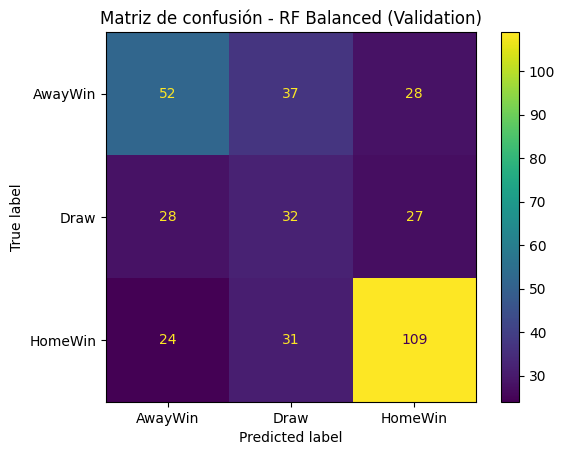

In [ ]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_estimator(
    rf_3,
    X_val,
    y_val_enc,
    display_labels=label_encoder.classes_
)

plt.title("Matriz de confusión - RF Balanced (Validation)")
plt.show()

El modelo Random Forest con ponderación de clases presenta un mejor equilibrio en la predicción de las tres clases, mejorando significativamente la detección de empates en comparación con los modelos anteriores. Aunque la precisión global es ligeramente inferior, el aumento en el F1-score macro indica una mayor capacidad del modelo para tratar el problema de clasificación multiclase de forma más equilibrada.

## MODELO ADICIONAL: XGBOOST

In [ ]:
!pip install xgboost

In [ ]:
from xgboost import XGBClassifier

xgb_clf = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=3,
    random_state=42
)

xgb_clf.fit(X_train, y_train_enc)

y_val_pred_xgb = xgb_clf.predict(X_val)

evaluar_modelo("XGBoost", y_val_enc, y_val_pred_xgb)


===== XGBoost =====
Accuracy: 0.4728
Macro F1: 0.3941

Classification report:
              precision    recall  f1-score   support

     AwayWin       0.52      0.32      0.40       117
        Draw       0.23      0.14      0.17        87
     HomeWin       0.51      0.76      0.61       164

    accuracy                           0.47       368
   macro avg       0.42      0.41      0.39       368
weighted avg       0.45      0.47      0.44       368


Confusion matrix:
[[ 38  15  64]
 [ 21  12  54]
 [ 14  26 124]]


Se ha llevado a cabo una inclusión de un modelo basado en gradient boosting (XGBoost), pero no ha supuesto una mejora en el rendimiento en validación respecto a los modelos previamente evaluados. De hecho, no ha dado resultados balanceados, dado que el recall del empate es tan sólo de un 14%.

Este resultado sugiere que la limitación principal no residen en la capacidad del modelo, sino en la naturaleza de los datos (dataset limitado y pequeño) y la dificultad intrínseca del problema a resolver.

### ELECCIÓN FINAL

In [ ]:
import pandas as pd

# Resultados de los modelos mejores en validación

results = pd.DataFrame({
    "Modelo": ["Logística Balanced", "RF Balanced", "XGBoost"],
    "Accuracy": [0.4592, 0.5245, 0.4728],
    "Macro_F1": [0.4423, 0.4925, 0.3941]
})

results

,Modelo,Accuracy,Macro_F1
0,Logística Balanced,0.4592,0.4423
1,RF Balanced,0.5245,0.4925
2,XGBoost,0.4728,0.3941


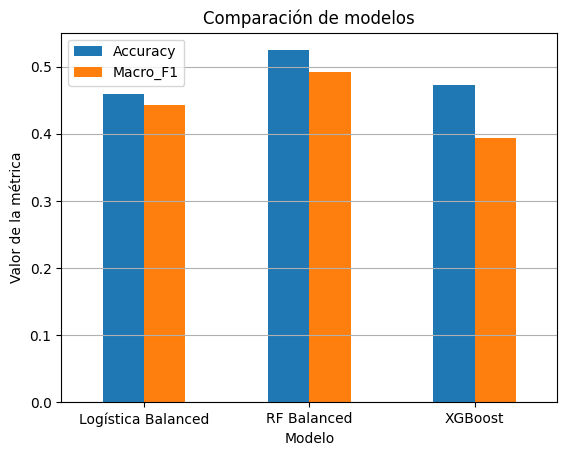

In [ ]:
import matplotlib.pyplot as plt

results.set_index("Modelo")[["Accuracy", "Macro_F1"]].plot(kind="bar")

plt.title("Comparación de modelos")
plt.ylabel("Valor de la métrica")
plt.xticks(rotation=0)
plt.legend()
plt.grid(axis="y")

plt.show()

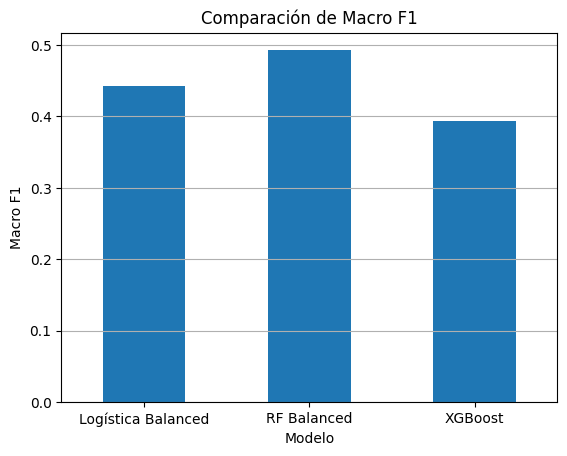

In [ ]:
results.set_index("Modelo")["Macro_F1"].plot(kind="bar")

plt.title("Comparación de Macro F1")
plt.ylabel("Macro F1")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

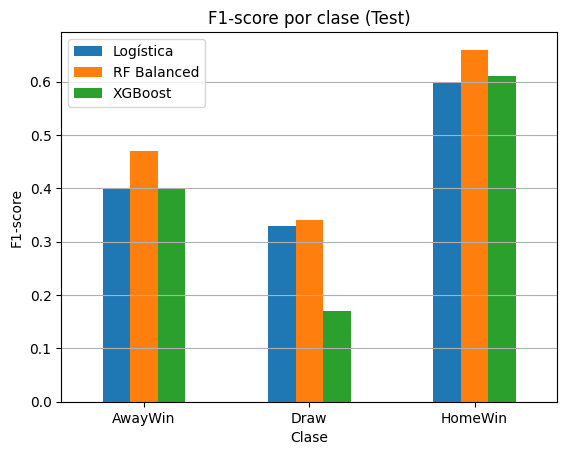

In [ ]:
import numpy as np

# F1 por clase
f1_scores = pd.DataFrame({
    "Clase": ["AwayWin", "Draw", "HomeWin"],
    "Logística": [0.40, 0.33, 0.60],
    "RF Balanced": [0.47, 0.34, 0.66],
    "XGBoost": [0.40, 0.17, 0.61]
})

f1_scores.set_index("Clase").plot(kind="bar")

plt.title("F1-score por clase (Test)")
plt.ylabel("F1-score")
plt.xticks(rotation=0)
plt.grid(axis="y")

plt.show()

Tras la evaluación final en el conjunto de test, se demuestra que el mejor modelo es Random Forest Balanced, ya que tiene mejor equilibrio y es ligeramente superior tanto en Accuracy como en Macro F1. Esto indica una mejor capacidad de generalización y un tratamiento más equilibrado de las diferentes clases, especialmente en un problema caracterizado por el desbalanceo y la incertidumbre inherente en fútbol.

Los resultados evidencias que la predicción de resultados es un problema complejo donde incluso modelos avanzados presentas limitaciones, especialmente en la predicción de empates

### CONJUNTO TEST

In [ ]:
modelo_final = rf_3

y_test_pred = rf_3.predict(X_test)

evaluar_modelo("Modelo final (RF balanced) - TEST", y_test_enc, y_test_pred)


===== Modelo final (RF balanced) - TEST =====
Accuracy: 0.4661
Macro F1: 0.4379

Classification report:
              precision    recall  f1-score   support

     AwayWin       0.44      0.41      0.42       102
        Draw       0.23      0.34      0.27        86
     HomeWin       0.69      0.56      0.62       181

    accuracy                           0.47       369
   macro avg       0.45      0.44      0.44       369
weighted avg       0.51      0.47      0.48       369


Confusion matrix:
[[ 42  40  20]
 [ 31  29  26]
 [ 23  57 101]]


Evaluamos y vemos el rendimiento del modelo elegido, Random Forest balanceado, en el conjunto test


Accuracy: 0.4661
Macro F1: 0.4379
Weighted F1: 0.4831
              precision    recall  f1-score     support
AwayWin        0.437500  0.411765  0.424242  102.000000
Draw           0.230159  0.337209  0.273585   86.000000
HomeWin        0.687075  0.558011  0.615854  181.000000
accuracy       0.466125  0.466125  0.466125    0.466125
macro avg      0.451578  0.435662  0.437894  369.000000
weighted avg   0.511597  0.466125  0.483118  369.000000


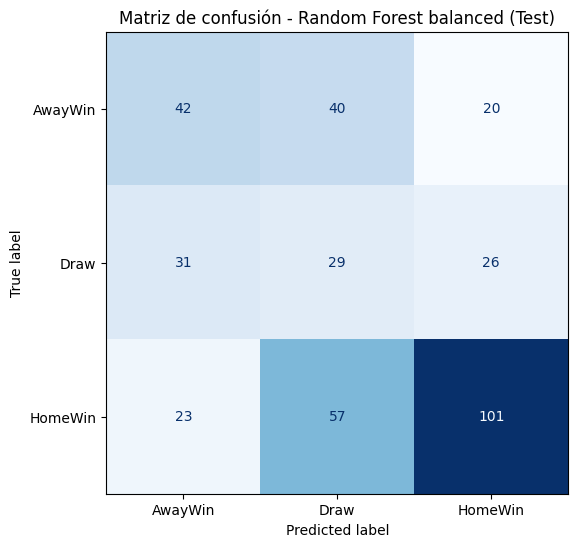

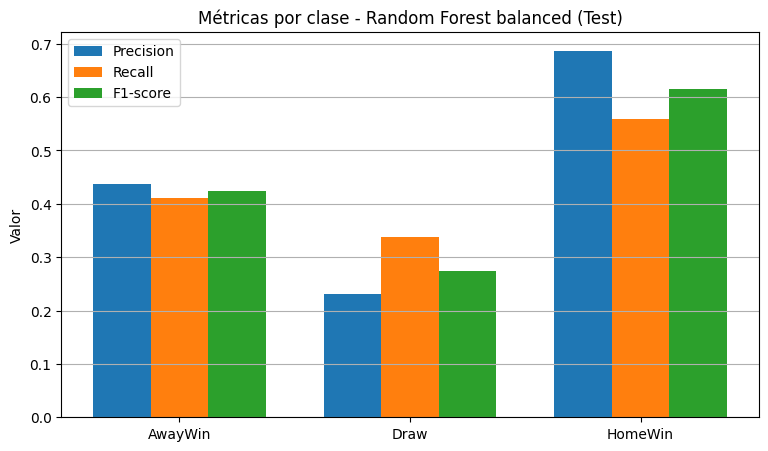

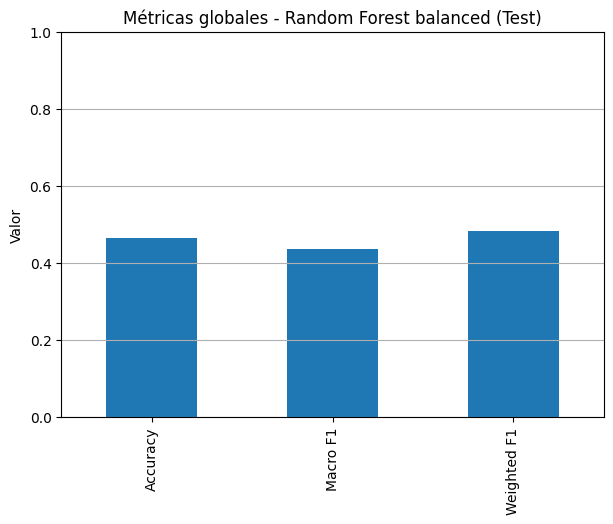

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    accuracy_score,
    f1_score
)

# =========================
# 1. Métricas globales
# =========================
accuracy = accuracy_score(y_test_enc, y_test_pred)
macro_f1 = f1_score(y_test_enc, y_test_pred, average="macro")
weighted_f1 = f1_score(y_test_enc, y_test_pred, average="weighted")

print("Accuracy:", round(accuracy, 4))
print("Macro F1:", round(macro_f1, 4))
print("Weighted F1:", round(weighted_f1, 4))

# =========================
# 2. Classification report como dataframe
# =========================
report_dict = classification_report(
    y_test_enc,
    y_test_pred,
    target_names=label_encoder.classes_,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report_dict).T
print(report_df)

# Nos quedamos solo con las clases
class_names = list(label_encoder.classes_)
report_classes_df = report_df.loc[class_names, ["precision", "recall", "f1-score"]]

# =========================
# 3. Matriz de confusión
# =========================
cm = confusion_matrix(y_test_enc, y_test_pred)

fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Matriz de confusión - Random Forest balanced (Test)")
plt.show()

# =========================
# 4. Métricas por clase
# =========================
x = np.arange(len(class_names))
width = 0.25

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(x - width, report_classes_df["precision"], width, label="Precision")
ax.bar(x, report_classes_df["recall"], width, label="Recall")
ax.bar(x + width, report_classes_df["f1-score"], width, label="F1-score")

ax.set_title("Métricas por clase - Random Forest balanced (Test)")
ax.set_ylabel("Valor")
ax.set_xticks(x)
ax.set_xticklabels(class_names)
ax.legend()
ax.grid(axis="y")
plt.show()

# =========================
# 5. Métricas globales
# =========================
global_metrics = pd.Series({
    "Accuracy": accuracy,
    "Macro F1": macro_f1,
    "Weighted F1": weighted_f1
})

fig, ax = plt.subplots(figsize=(7, 5))
global_metrics.plot(kind="bar", ax=ax)
ax.set_title("Métricas globales - Random Forest balanced (Test)")
ax.set_ylabel("Valor")
ax.set_ylim(0, 1)
ax.grid(axis="y")
plt.show()

In [ ]:
ruta_figuras = Path('/content/drive/MyDrive/TU_RUTA/Dataset')
ruta_figuras.mkdir(parents=True, exist_ok=True)

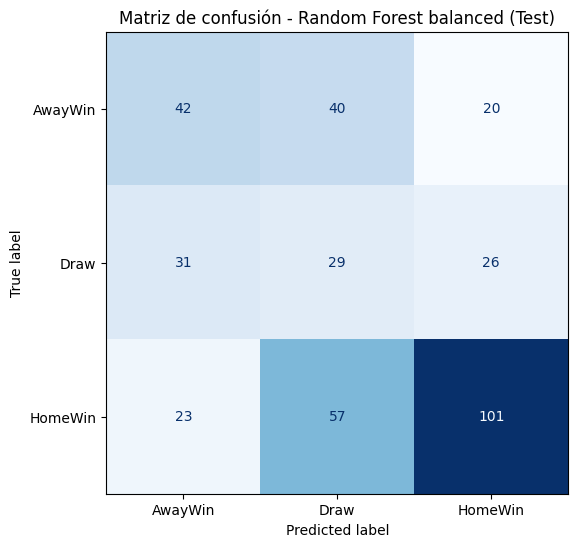

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Matriz de confusión - Random Forest balanced (Test)")
plt.savefig(ruta_figuras / "matriz_confusion_rf_balanced_test.png", dpi=300, bbox_inches="tight")
plt.show()

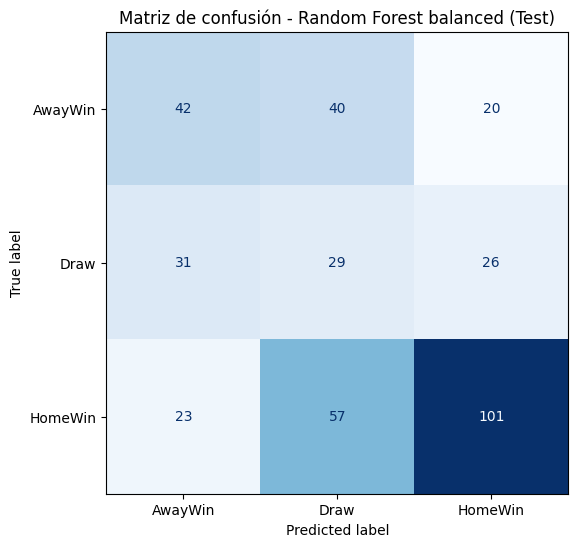

In [ ]:
fig, ax = plt.subplots(figsize=(7, 6))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
disp.plot(ax=ax, cmap="Blues", colorbar=False)
plt.title("Matriz de confusión - Random Forest balanced (Test)")
plt.savefig(ruta_figuras / "matriz_confusion_rf_balanced_test.png", dpi=300, bbox_inches="tight")
plt.show()

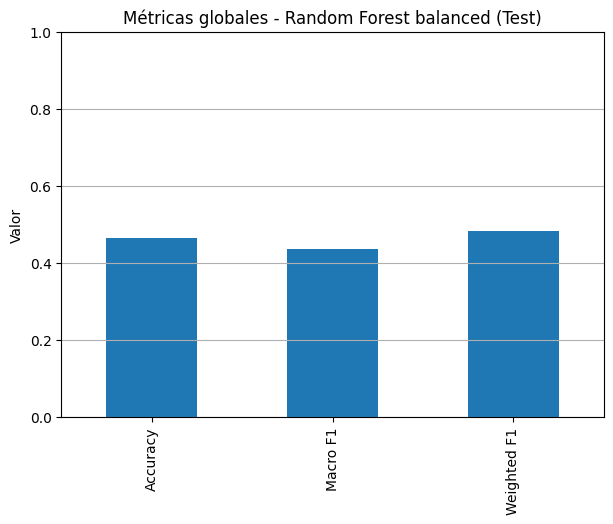

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
global_metrics.plot(kind="bar", ax=ax)
ax.set_title("Métricas globales - Random Forest balanced (Test)")
ax.set_ylabel("Valor")
ax.set_ylim(0, 1)
ax.grid(axis="y")

plt.savefig(ruta_figuras / "metricas_globales_rf_balanced_test.png", dpi=300, bbox_inches="tight")
plt.show()